# Section 1: Plant growth modelling

Modeling Biosystems - Group 3A

## 1. Imports

Load NumPy, Matplotlib, the SciPy ODE solver, and the least-squares fitting function.

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares


## 2. Model parameters

Set the reaction rate constants and the kinetic parameters used by the model. Assemble the full parameter vector in the order [k1, km1, k2, km2, kcat, KM, k3, k4, k5].

In [40]:
# Parameters
k1 = 1.0
km1 = 0.01
k2 = 0.5
km2 = 0.2

kcat = 0.15
KM = 1.0

k3 = 0.01
k4 = 0.1
k5 = 0.008

# Full model parameter vector: [k1, km1, k2, km2, kcat, KM, k3, k4, k5]
parameters = np.array([k1, km1, k2, km2, kcat, KM, k3, k4, k5], dtype=float)


## 3. Initial concentrations

Define the starting ligand, receptor, and cytoplasmic transcription factor concentrations. vector: L, R, LR, LRa, TFc, pTFc, pTFn, TFn.

In [41]:
# Initial concentrations
L0 = 0.3
R0 = 1.0
TFc0 = 1.0

# Species = [L, R, LR, LRa, TFc, pTFc, pTFn, TFn]


## 4. Differential equations

Define the rate of change for each species in plant_growth(t, y, parameters).

Pass the full parameter vector in the order [k1, km1, k2, km2, kcat, KM, k3, k4, k5]. The model unpacks every rate from this vector, so any parameter can be varied without changing global variables or the model equations.

In [42]:
# Differential equations
def plant_growth(t, y, parameters):
    """Return species derivatives for [k1, km1, k2, km2, kcat, KM, k3, k4, k5]."""
    k1, km1, k2, km2, kcat, KM, k3, k4, k5 = parameters

    L, R, LR, LRa, TFc, pTFc, pTFn, TFn = y

    dL = -k1*L*R + km1*LR + km2*LRa #hormone
    dR = -k1*L*R + km1*LR + km2*LRa #receptor
    dLR = k1*L*R - km1*LR - k2*LR
    dLRa = k2*LR - km2*LRa

    dTFc = -kcat*LRa*TFc/(KM + TFc) + k5*TFn
    dpTFc = kcat*LRa*TFc/(KM + TFc) - k3*pTFc
    dpTFn = k3*pTFc - k4*pTFn
    dTFn = k4*pTFn - k5*TFn

    return [dL, dR, dLR, dLRa, dTFc, dpTFc, dpTFn, dTFn]


## 5. Initial conditions

Set the remaining starting concentrations and assemble the initial state vector y0 in the model's species order.

In [ ]:
# Script main()

#initial conditions
LR0, LRa0, pTFc0, pTFn0, TFn0 = 0, 0, 0, 0, 0
y0 = [L0, R0, LR0, LRa0, TFc0, pTFc0, pTFn0, TFn0]

## 6. Simulation time

Simulate from time 0 to 500 and request results at 1,000 evenly spaced time points.

In [44]:
#Time interval 
time_interval = (0, 500)
time_points = np.linspace(*time_interval, 1000)


## 7. Solve the ODE system

Integrate the model with solve_ivp using the initial conditions and the requested time points.

In [45]:
#Solve the ODE system
solution = solve_ivp(
    plant_growth,
    time_interval,
    y0,
    t_eval=time_points,
    args=(parameters,)  # Pass the full vector as one argument using the Table 1 rates.
)


## 8. Extract results

Read the time points returned by the solver and unpack the species concentration arrays.

In [46]:
#Extract results
time_points_evaluation = solution.t # since the function could have stopped earlier than our initial time_points it is good to get them from the solution 
L, R, LR, LRa, TFc, pTFc, pTFn, TFn = solution.y


## 9. Plot species concentrations

Show each species concentration over time in its own subplot.

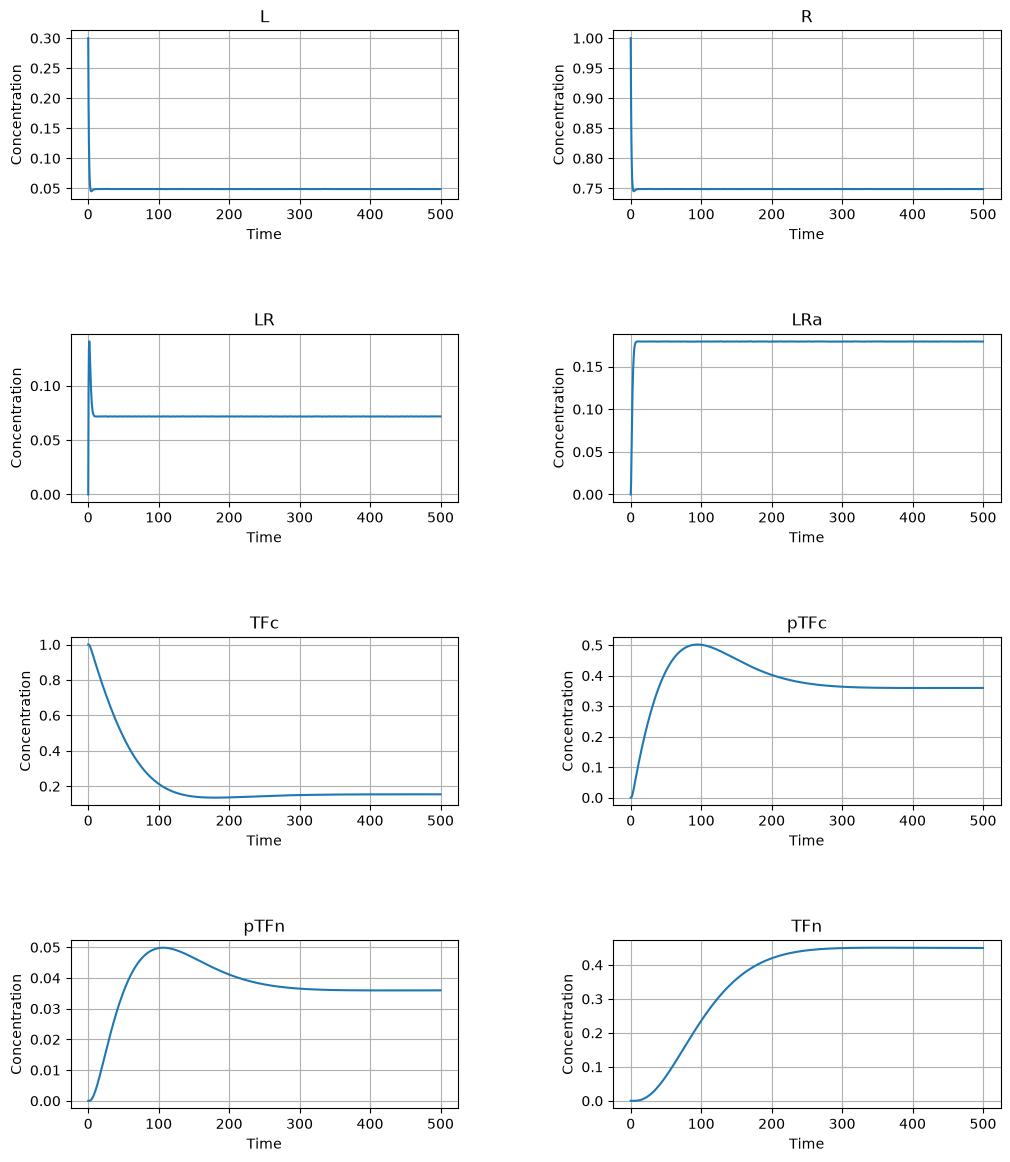

In [47]:
#Ploting our solution
species = ["L", "R", "LR", "LRa", "TFc", "pTFc", "pTFn", "TFn"]

fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for i, ax in enumerate(axes.flat):
    ax.plot(time_points_evaluation, solution.y[i])
    ax.set_title(species[i])
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentration")
    ax.grid(True)

plt.subplots_adjust(hspace=0.8, wspace=0.4)

plt.show()


### 9.1 Analysis of plots
##### 1. Ligand (L)
The ligand concentration decreases rapidly as there are free receptors that it can bind to. Then it elevates slightly as receptor complexes dissociate and converges to 0.0489 concentration.
##### 2. Receptor (R)
The receptor behaves very similarly to the ligand as it coverges to 0.7489 due to the higher initial concentration.
##### 3. Ligand–receptor complex (LR)
The complex increases rapidly in the beginning reaching a peak concentration and then it decrases and converges to 0.0718 as it decosiates into L and R or is converted to LRa.
##### 4. Activated receptor (LRa)
The activated receptor increases rapidly as LR starts being activated and converges to 0.1794 as the formation and disociation balance out.   
##### 5. Cytoplasmic unphosphorylated TF (TFc)
The transcription factor's concentration decreases quite a lot as it reaches a minimal level and then reconvers as transcription factor returns from the nucleus and converges to 0.1544.
##### 6. Cytoplasmic phosphorylated TF (pTFc)
The phosphorilated Transcription factor initially increases as cytoplasmic TF gets phosphorilated. It reaches a peak and then converges to 0.3597 as the available TFc falls.
##### 7. Nuclear phosphorylated TF (pTFn)
pTFn starts at zero and increases when pTFc enters the nucleus. It follows the peak and decrease of pTFc a bit delated as it is transported from the cytoplasm. It decreases as dephosphorilation happens and converges to 0.0360.
##### 8. Nuclear unphosphorylated TF (TFn)
TFn gradually increase and reaches it's peak and converges to 0.4499 as the dephosphorylation rate matches the transport out of the nucleus. 

## 10. Calculate conserved totals

Calculate the total ligand, receptor, and transcription factor concentrations by summing their corresponding species.

In [48]:
# Mass conservation

L_total = L + LR + LRa
R_total = R + LR + LRa
TF_total = TFc + pTFc + pTFn + TFn


## 11. Plot mass conservation

Compare the three totals over time to inspect mass conservation.

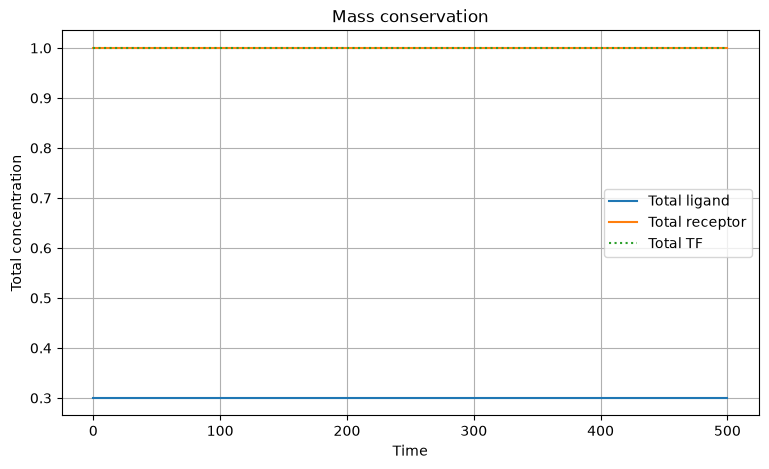

In [49]:
#Plotting Mass consevation

plt.figure(figsize=(9, 5))

plt.plot(solution.t, L_total, label="Total ligand" )
plt.plot(solution.t, R_total, label="Total receptor", )
plt.plot(solution.t, TF_total, label="Total TF", ls="dotted")

plt.xlabel("Time")
plt.ylabel("Total concentration")
plt.title("Mass conservation")
plt.legend()
plt.grid(True)
plt.show()


As expected the total concentration does not change.

#### Step 5


## 12. Parameter estimation (Step 6)

We want to find values of **k3** and **k4** that make the model's nuclear phosphorylated transcription factor concentration, **pTFn**, agree with the measurements in Table 3 from the aissnment.

- k3 controls the movement of pTFc from the cytoplasm into the nucleus.
- k4 controls the dephosphorylation of pTFn in the nucleus.

**Assumptions:** all other rates and initial concentrations stay at the values defined above. L0 = 0.3, R0 = 1.0, and TFc0 = 1.0; the other initial concentrations are zero.

### 12.1 Data

The data from Table 3

In [50]:
# Table 3 from the assignment.
measurement_times = np.array([10, 20, 30, 45, 60, 80, 100])
measured_pTFn = np.array([0.0080, 0.0206, 0.0404, 0.0671, 0.0844, 0.0992, 0.1022])


### 12.2 Simulate pTFn with some rate estimate

This function runs the model with a full parameter vector and returns the model's pTFn concentrations. During fitting, we vary only k3 and k4 within a copy of the original vector.

The simulation will start at 0 even though the first data point is at 10. setting t_eval will give us the data points at the evaluation times we want.

The smaller rtol and atol values give us more accurate numerical solution.

In [51]:
def simulate_pTFn(parameters, evaluation_times):
    """Return the model's pTFn concentrations at the requested times."""
    simulation = solve_ivp(
        plant_growth,
        t_span=(0, evaluation_times[-1]), # -1 gives us the last element
        y0=y0,
        t_eval=evaluation_times, # at which times we save the simulated value
        args=(parameters,),
        rtol=1e-7,
        atol=1e-9
    )

    # pTFn is returned. It is a vector comprising of all the pTFn at each time point
    return simulation.y[6]


### 12.3 Calculating the differences between model and data
Here we calculate the residuals. A residual is the model prediction minus the measured value at one time point. This function returns all the residuals for all data paoints.

least_squares will try different pairs of rates to make the sum of the squared residuals as small as possible.

In [52]:
def pTFn_residuals(rates):
    # The optimizer supplies two numbers in the order [k3, k4].
    trial_parameters = parameters.copy()
    trial_parameters[6:8] = rates  # Replace k3 and k4; keep all other rates fixed.

    predicted_pTFn = simulate_pTFn(trial_parameters, measurement_times)
    residuals = predicted_pTFn - measured_pTFn
    return residuals


### 12.4 Estimate k3 and k4

We start the search at the original Table 1 rates. The lower bounds prevent negative rate constants. np.inf means that we do not set an upper bound for the rates

fit_result.x contains the two rates fitted from the data.

In [53]:
initial_guess = parameters[6:8].copy()  # Original k3 and k4 as the starting point.
lower_bounds = [0, 0]
upper_bounds = [np.inf, np.inf]

fit_result = least_squares(
    pTFn_residuals,
    x0=initial_guess,
    bounds=(lower_bounds, upper_bounds)
) 
""" 
what least_squares does is that it will call the resifuals function
whith new guessed values until it succeeds to converge to a solution
"""
k3_fitted, k4_fitted = fit_result.x
fitted_parameters = parameters.copy()
fitted_parameters[6:8] = fit_result.x  # Store the fitted k3 and k4 in the full vector.

print(f"k3: original = {k3:.5f}, fitted = {k3_fitted:.5f}")
print(f"k4: original = {k4:.5f}, fitted = {k4_fitted:.5f}")


k3: original = 0.01000, fitted = 0.01601
k4: original = 0.10000, fitted = 0.06017


### 12.5 Quantify the fit with RMSE

The root-mean-square error (RMSE) measures the typical size of the model-data differences. The smaller value the better.

$$
\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}
\left(pTFn_{\mathrm{model}}(t_i)-pTFn_{\mathrm{measured}}(t_i)\right)^2},
\qquad N=7.
$$

We calculate this at the seven measurement times, for both the original and fitted rates.

In [54]:
# Predict pTFn once more with the old and new values
original_at_measurements = simulate_pTFn(parameters, measurement_times)
fitted_at_measurements = simulate_pTFn(fitted_parameters, measurement_times)

# Square each difference, take the mean, then take the square root.
original_rmse = np.sqrt(np.mean((original_at_measurements - measured_pTFn)**2))
fitted_rmse = np.sqrt(np.mean((fitted_at_measurements - measured_pTFn)**2))

print(f"RMSE with original rates: {original_rmse:.6f}")
print(f"RMSE with fitted rates:   {fitted_rmse:.6f}")


RMSE with original rates: 0.035974
RMSE with fitted rates:   0.001109


Fitting these parameters reduces the error with about 97%.

### 12.6 Comparison of the measurements

To make the curves smoother we simulate at more points. We can see the two models on the plot.

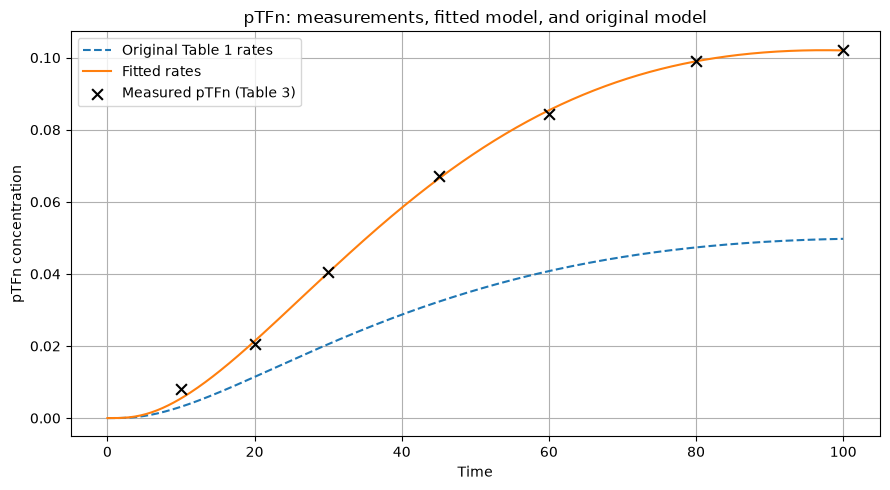

In [55]:
comparison_times = np.linspace(0, measurement_times[-1], 400)
original_curve = simulate_pTFn(parameters, comparison_times)
fitted_curve = simulate_pTFn(fitted_parameters, comparison_times)

plt.figure(figsize=(9, 5))
plt.plot(comparison_times, original_curve, "--", label="Original Table 1 rates")
plt.plot(comparison_times, fitted_curve, label="Fitted rates")
plt.scatter(
    measurement_times,
    measured_pTFn,
    color="black",
    marker="x",
    s=60,
    label="Measured pTFn (Table 3)",
    zorder=3
)

plt.xlabel("Time")
plt.ylabel("pTFn concentration")
plt.title("pTFn: measurements, fitted model, and original model")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### 12.7 Interpretation

The estinated rates are k3 approximately 0.01601 and k4 approximately 0.06017. The RMSE decreases from approximately 0.035974 with the original rates to 0.001109 after we estimate the new rates.

The larger k3 means faster transport of pTFc into the nucleus. The smaller k4 means slower removal of pTFn by dephosphorylation. Together, these changes increase the predicted pTFn concentration and bring the model much closer to the measured values.

Having larger k3 means that there is a faster transport of pTFc to the nucleus and the smaller k4 means that the dephosphorilation of pTFn is slower. These allow the model to match measured data much closer. 

We just want to meantion that fitting the data better does not nessesarily mean that the model is better or it will generalise better. With another set of data the new model may be worse that the original model.

#### Step 7
`RQ:` How do different species' characteristics vary in respect to baseline parameter values?

1. Define plant specie differences and model specie adjustment function

In [56]:
arabidopsis_thaliana = [0.5, -0.3, 0, 0, 0, 0, 0, 0]
arabidopsis_thaliana_parameters = [0, 0, 0.2, 0, 0, 0, 0, -0.1, 0]
tomato = [0.2, 0.1, 0, 0, 0, 0, 0, 0]
tomato_parameters = [0, 0, -0.15, 0, 0, 0, 0, -0.2, 0]
maize = [-0.1, 0.5, 0, 0, 0, 0, 0, 0]
maize_parameters = [0, 0, 0.5, 0, 0, 0, 0, 0.35, 0]
pea = [0.1, -0.15, 0, 0, 0, 0, 0, 0]
pea_parameters = [0, 0, -0.3, 0, 0, 0, 0, 0.05, 0]
rice = [-0.2, 0.2, 0, 0, 0, 0, 0, 0]
rice_parameters = [0, 0, 0.05, 0, 0, 0, 0, 0.1, 0]

def calculate_change(sp_vector, adjustment_weights, sp_index):
    sp = sp_vector[sp_index]
    adj_weight = adjustment_weights[sp_index]
    return sp + sp*adj_weight

def adjust_vector_with_weights(vector, adjustment_weights):
    """Return an adjusted copy without modifying the input vector."""
    adjusted = np.array(vector, dtype=float, copy=True)
    for i in range(len(vector)):
        adjusted[i] = calculate_change(vector, adjustment_weights, i)
    return adjusted

2. Run for all species

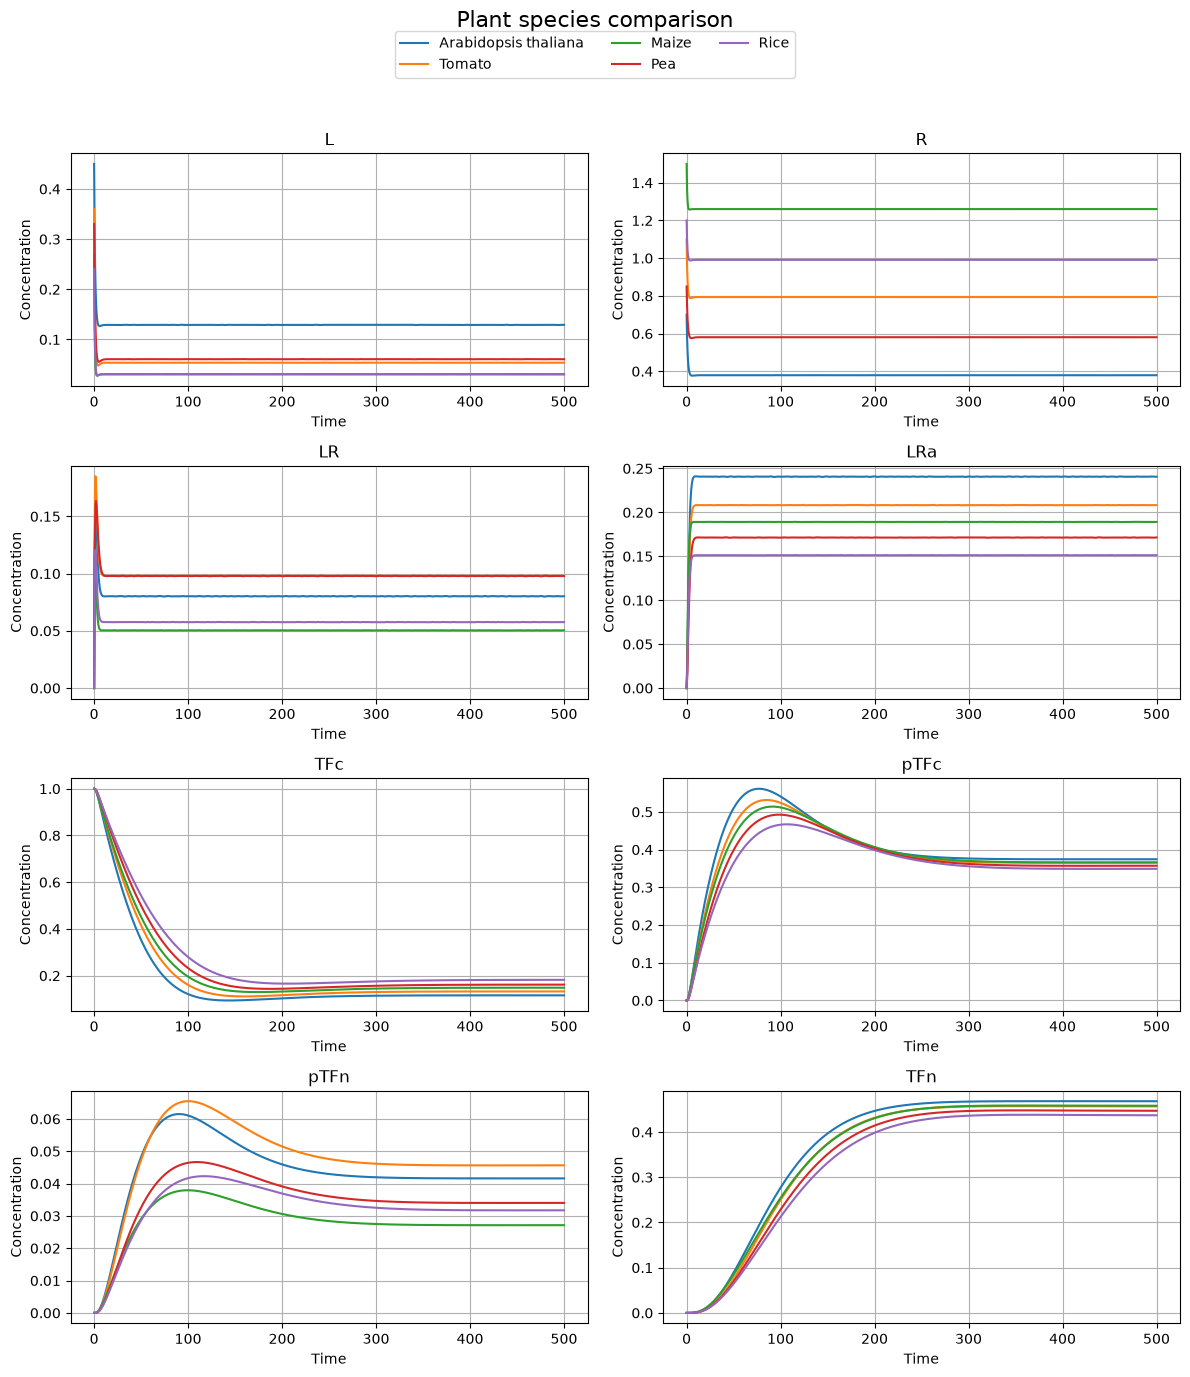

In [57]:
plant_names = ["Arabidopsis thaliana", "Tomato", "Maize", "Pea", "Rice"]
specie_set_y0 = [
    adjust_vector_with_weights(y0, adj)
    for adj in [arabidopsis_thaliana, tomato, maize, pea, rice]
]
specie_set_parameters = [
    adjust_vector_with_weights(parameters, adj)
    for adj in [
        arabidopsis_thaliana_parameters, tomato_parameters,
        maize_parameters, pea_parameters, rice_parameters
    ]
]

# Simulate each plant using its adjusted initial conditions and parameters.
solutions = []
for plant_name, plant_y0, plant_parameters in zip(
    plant_names, specie_set_y0, specie_set_parameters
):
    plant_solution = solve_ivp(
        plant_growth,
        time_interval,
        plant_y0,
        t_eval=time_points,
        args=(plant_parameters,)
    )
    solutions.append(plant_solution)

# One subplot per model species, with one line per plant.
fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for i, ax in enumerate(axes.flat):
    for plant_name, plant_solution in zip(plant_names, solutions):
        ax.plot(plant_solution.t, plant_solution.y[i], label=plant_name)
    ax.set_title(species[i])
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentration")
    ax.grid(True)

# The same plant colors are used across all eight subplots.
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.suptitle("Plant species comparison", fontsize=16)
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


# Section 2: Parcial Differencial Equations